# AI-Powered Pneumonia Detection from Chest X-Rays

**Notebook:** end-to-end binary image-classification experiment using the *Chest X-Ray Images (Pneumonia)* dataset.

This notebook compares three approaches:

1. **Custom CNN** — baseline trained from scratch.
2. **DenseNet121** — ImageNet-pretrained transfer-learning model.
3. **EfficientNetB0** — ImageNet-pretrained transfer-learning model.

It includes dataset exploration, a stratified validation split, class weighting, training-only data augmentation, model evaluation, comparison plots, Grad-CAM visualizations, and prediction for a new X-ray image.

> **Important:** This is an educational machine-learning project, not a clinically validated diagnostic system. The dataset is pediatric and its performance may not generalize to other populations, hospitals, or imaging equipment. A Grad-CAM heatmap is only a model-inspection aid and does not prove that a prediction is medically correct.

## How to run

- Recommended: open this notebook in **Google Colab**, choose **Runtime → Change runtime type → T4 GPU** (or another available GPU), then run cells from top to bottom.
- The dataset is downloaded through KaggleHub when internet access permits. If that fails, download the dataset manually from [Kaggle](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia), extract it, and set `DATA_ROOT_OVERRIDE` in the dataset cell to the folder containing `train/` and `test/`.
- The notebook creates a new validation split from the original training folder because the dataset's supplied validation folder is very small. The original `test/` folder is kept separate and is used only for final evaluation.

**Expected dataset layout** (the root folder can be nested one level deeper):

```text
chest_xray/
├── train/
│   ├── NORMAL/
│   └── PNEUMONIA/
├── val/          # supplied validation folder is not used
└── test/
    ├── NORMAL/
    └── PNEUMONIA/
```

## 1. Install required packages

In [1]:
%pip -q install kagglehub scikit-learn pandas matplotlib pillow

## 2. Import libraries and configure the experiment

In [2]:
import os
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_SIZE = 0.15
EPOCHS_HEAD = 5          # increase for a longer experiment
EPOCHS_FINE_TUNE = 3     # increase for a longer experiment
FINE_TUNE_LAST_N = 30
ENABLE_FINE_TUNING = True
AUTOTUNE = tf.data.AUTOTUNE
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]  # sorted folder names; label 0 and 1 respectively

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("Tip: use a GPU runtime for faster transfer-learning experiments. CPU training may be slow.")

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Download or locate the dataset

In [3]:
# Leave this as None for an automatic KaggleHub download.
# If you downloaded/extracted the dataset manually, set it to the folder
# that contains train/ and test/, e.g. Path("/content/chest_xray").
DATA_ROOT_OVERRIDE = None
DATASET_SLUG = "paultimothymooney/chest-xray-pneumonia"

SUPPORTED_EXTENSIONS = {".jpeg", ".jpg", ".png", ".bmp"}

def is_dataset_root(path: Path) -> bool:
    """True when path contains train/ and test/ with both class folders."""
    try:
        return all(
            (path / split / cls).is_dir()
            for split in ("train", "test")
            for cls in CLASS_NAMES
        )
    except (TypeError, OSError):
        return False

def locate_dataset_root(start: Path):
    """Find a dataset root even when the downloaded archive has an extra nested folder."""
    start = Path(start)
    if is_dataset_root(start):
        return start
    if not start.exists():
        return None
    # Search for likely train folders rather than relying on one fixed KaggleHub path.
    for train_folder in start.rglob("train"):
        candidate = train_folder.parent
        if is_dataset_root(candidate):
            return candidate
    return None

DATA_ROOT = None
if DATA_ROOT_OVERRIDE is not None:
    DATA_ROOT = locate_dataset_root(Path(DATA_ROOT_OVERRIDE))
else:
    try:
        import kagglehub
        downloaded_path = Path(kagglehub.dataset_download(DATASET_SLUG))
        print("KaggleHub downloaded/cached dataset at:", downloaded_path)
        DATA_ROOT = locate_dataset_root(downloaded_path)
    except Exception as exc:
        print("Automatic download did not work:", repr(exc))
        print("You can download the dataset manually from the Kaggle page linked in the notebook introduction.")

if DATA_ROOT is None:
    # Common paths in Colab and local notebooks; edit DATA_ROOT_OVERRIDE above if yours differs.
    for candidate in [Path("/content/chest_xray"), Path("/content/chest-xray-pneumonia"), Path("./chest_xray")]:
        DATA_ROOT = locate_dataset_root(candidate)
        if DATA_ROOT is not None:
            break

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find train/NORMAL, train/PNEUMONIA, test/NORMAL, and test/PNEUMONIA folders. "
        "Download/extract the Kaggle dataset, set DATA_ROOT_OVERRIDE to the dataset root, and rerun this cell."
    )

DATA_ROOT = Path(DATA_ROOT)
print("Using dataset root:", DATA_ROOT)
print("Training folder found:", (DATA_ROOT / "train").is_dir())
print("Test folder found:", (DATA_ROOT / "test").is_dir())

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
KaggleHub downloaded/cached dataset at: /kaggle/input/chest-xray-pneumonia
Using dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
Training folder found: True
Test folder found: True


## 4. Explore class counts and create a stratified train/validation split

,Split,Total,NORMAL,PNEUMONIA,NORMAL %,PNEUMONIA %
0,Train,4433,1140,3293,25.72,74.28
1,Validation,783,201,582,25.67,74.33
2,Test,624,234,390,37.50,62.50


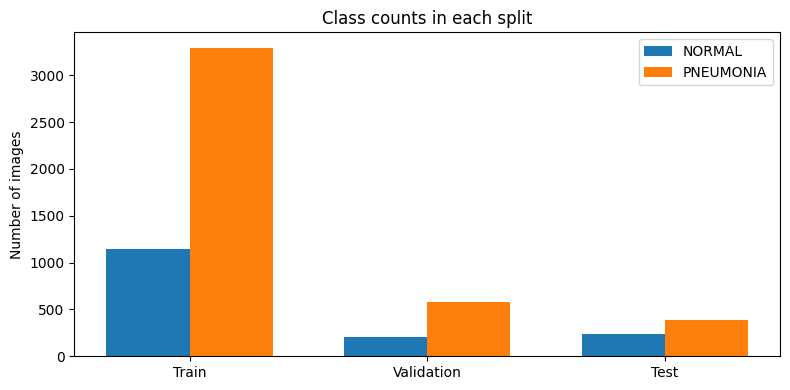

Note: this is a stratified file-level split. The source dataset does not provide enough patient identifiers here to guarantee patient-level separation.


In [4]:
def list_images(folder: Path):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    )

all_train_paths, all_train_labels = [], []
for label, class_name in enumerate(CLASS_NAMES):
    files = list_images(DATA_ROOT / "train" / class_name)
    all_train_paths.extend([str(p) for p in files])
    all_train_labels.extend([label] * len(files))

all_test_paths, all_test_labels = [], []
for label, class_name in enumerate(CLASS_NAMES):
    files = list_images(DATA_ROOT / "test" / class_name)
    all_test_paths.extend([str(p) for p in files])
    all_test_labels.extend([label] * len(files))

all_train_paths = np.asarray(all_train_paths)
all_train_labels = np.asarray(all_train_labels, dtype=np.int32)
test_paths = np.asarray(all_test_paths)
test_labels = np.asarray(all_test_labels, dtype=np.int32)

if len(all_train_paths) == 0 or len(test_paths) == 0:
    raise ValueError("No images found. Check the dataset root and class subfolders.")
if set(np.unique(all_train_labels)) != {0, 1} or set(np.unique(test_labels)) != {0, 1}:
    raise ValueError("Both NORMAL and PNEUMONIA folders must contain supported image files in train/ and test/.")

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_train_paths,
    all_train_labels,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=all_train_labels,
)

def split_summary(name, labels):
    counts = np.bincount(labels, minlength=len(CLASS_NAMES))
    total = len(labels)
    return {
        "Split": name,
        "Total": total,
        "NORMAL": int(counts[0]),
        "PNEUMONIA": int(counts[1]),
        "NORMAL %": round(100 * counts[0] / total, 2) if total else 0,
        "PNEUMONIA %": round(100 * counts[1] / total, 2) if total else 0,
    }

split_df = pd.DataFrame([
    split_summary("Train", train_labels),
    split_summary("Validation", val_labels),
    split_summary("Test", test_labels),
])
display(split_df)

plt.figure(figsize=(8, 4))
x = np.arange(len(split_df))
width = 0.35
plt.bar(x - width / 2, split_df["NORMAL"], width, label="NORMAL")
plt.bar(x + width / 2, split_df["PNEUMONIA"], width, label="PNEUMONIA")
plt.xticks(x, split_df["Split"])
plt.ylabel("Number of images")
plt.title("Class counts in each split")
plt.legend()
plt.tight_layout()
plt.show()

print("Note: this is a stratified file-level split. The source dataset does not provide enough patient identifiers here to guarantee patient-level separation.")

## 5. View example images

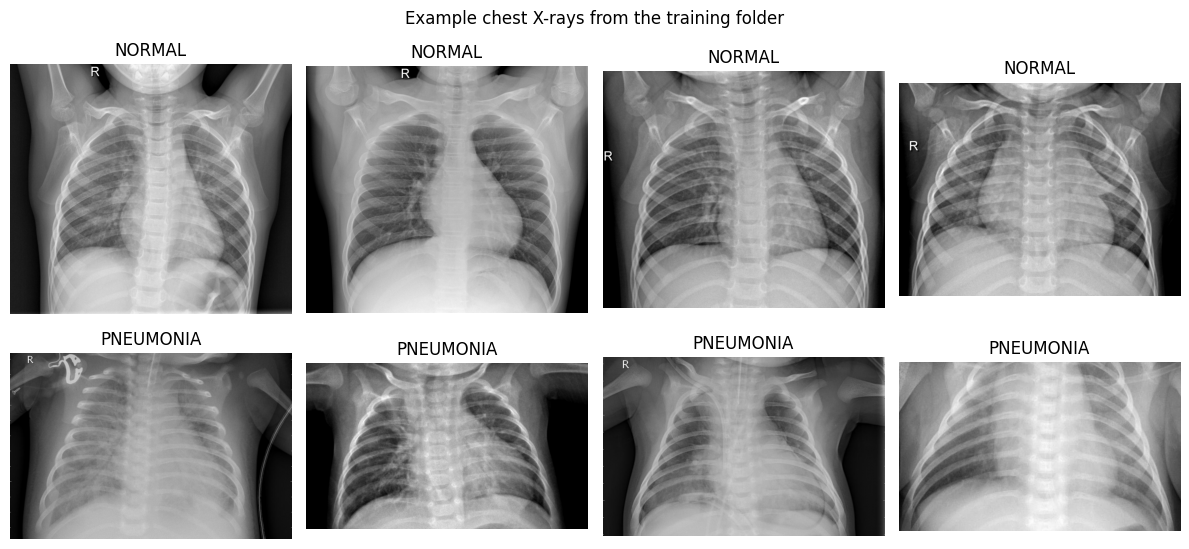

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, class_name in enumerate(CLASS_NAMES):
    class_files = [p for p, y in zip(all_train_paths, all_train_labels) if y == row]
    for col in range(4):
        ax = axes[row, col]
        if class_files:
            image_path = class_files[(col * max(1, len(class_files) // 4)) % len(class_files)]
            with Image.open(image_path) as im:
                ax.imshow(im.convert("L"), cmap="gray")
            ax.set_title(class_name)
        ax.axis("off")
plt.suptitle("Example chest X-rays from the training folder")
plt.tight_layout()
plt.show()

## 6. Build TensorFlow input pipelines

In [6]:
def decode_and_resize(path, label):
    contents = tf.io.read_file(path)
    image = tf.io.decode_image(contents, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    # tf.image.resize returns float32 values on approximately the original 0..255 pixel scale.
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    label = tf.cast(label, tf.int32)
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths.astype(str), labels.astype(np.int32)))
    if training:
        ds = ds.shuffle(min(len(paths), 2000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels, training=False)
test_ds = make_dataset(test_paths, test_labels, training=False)

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel value range: 0.0 to 254.70034790039062


## 7. Handle class imbalance with class weights

In [7]:
classes = np.array([0, 1], dtype=np.int32)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=train_labels)
class_weights = {int(cls): float(weight) for cls, weight in zip(classes, weights)}

weight_df = pd.DataFrame({
    "Class ID": classes,
    "Class": CLASS_NAMES,
    "Training images": [int(np.sum(train_labels == cls)) for cls in classes],
    "Class weight": [class_weights[int(cls)] for cls in classes],
})
display(weight_df)
print("The minority class receives a larger loss weight. Do not resample or augment the validation/test sets.")

,Class ID,Class,Training images,Class weight
0,0,NORMAL,1140,1.944298
1,1,PNEUMONIA,3293,0.673094


The minority class receives a larger loss weight. Do not resample or augment the validation/test sets.


## 8. Define models

All models use the same train/validation/test split and output two softmax scores (`NORMAL`, `PNEUMONIA`). The pretrained models are first trained with their feature extractor frozen, then (optionally) fine-tuned at a low learning rate. Data augmentation is active only while training.

In [8]:
def make_augmentation(name="data_augmentation"):
    # Mild augmentations only; no vertical flips or aggressive image transformations.
    return keras.Sequential([
        layers.RandomRotation(0.02),
        layers.RandomZoom(0.05),
        layers.RandomContrast(0.10),
    ], name=name)

@keras.utils.register_keras_serializable(package="PneumoniaProject")
class DenseNetPreprocessing(layers.Layer):
    """Serializable DenseNet preprocessing layer for raw 0..255 pixel input."""
    def call(self, inputs):
        return tf.keras.applications.densenet.preprocess_input(inputs)

def build_custom_cnn():
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name="xray")
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)
    for filters, block in [(32, 1), (64, 2), (128, 3), (256, 4)]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"block{block}_conv")(x)
        x = layers.BatchNormalization(name=f"block{block}_bn")(x)
        x = layers.Activation("relu", name=f"block{block}_relu")(x)
        x = layers.MaxPooling2D(name=f"block{block}_pool")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.35, name="dropout_head")(x)
    outputs = layers.Dense(2, activation="softmax", name="class_probs")(x)
    model = keras.Model(inputs, outputs, name="custom_cnn")
    return model, None

def build_transfer_model(architecture):
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name="xray")
    x = make_augmentation()(inputs)

    if architecture == "DenseNet121":
        backbone = keras.applications.DenseNet121(
            include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
        )
        x = DenseNetPreprocessing(name="densenet_preprocess")(x)
    elif architecture == "EfficientNetB0":
        backbone = keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
        )
        # EfficientNetB0 includes its own input rescaling/normalization layers.
        # Pass pixel values on the 0..255 scale into the backbone.
    else:
        raise ValueError(f"Unknown architecture: {architecture}")

    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.30, name="dropout_head")(x)
    outputs = layers.Dense(2, activation="softmax", name="class_probs")(x)
    model = keras.Model(inputs, outputs, name=architecture.lower())
    return model, backbone

# These objects are created below and saved in dictionaries for comparison.
trained_models = {}
backbones = {}
histories = {}
validation_results = {}
test_results = {}
print("Model builders are ready.")

Model builders are ready.


## 9. Training helpers

In [9]:
def compile_for_training(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=1, min_lr=1e-7, verbose=1
        ),
    ]

def combine_histories(history_objects):
    combined = {}
    for hist in history_objects:
        for key, values in hist.history.items():
            combined.setdefault(key, []).extend(values)
    return combined

def train_model(model_name, model, backbone=None):
    history_objects = []
    compile_for_training(model, learning_rate=1e-3 if backbone is None else 1e-3)
    print(f"\nTraining {model_name} — initial stage")
    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_HEAD,
        class_weight=class_weights,
        callbacks=make_callbacks(),
        verbose=1,
    )
    history_objects.append(hist)

    if backbone is not None and ENABLE_FINE_TUNING and EPOCHS_FINE_TUNE > 0:
        print(f"\nFine-tuning the last layers of {model_name}")
        backbone.trainable = True
        cutoff = max(0, len(backbone.layers) - FINE_TUNE_LAST_N)
        for index, layer in enumerate(backbone.layers):
            # Keep early feature layers and all BatchNormalization layers frozen for stability.
            layer.trainable = index >= cutoff and not isinstance(layer, layers.BatchNormalization)
        compile_for_training(model, learning_rate=1e-5)
        hist_ft = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS_FINE_TUNE,
            class_weight=class_weights,
            callbacks=make_callbacks(),
            verbose=1,
        )
        history_objects.append(hist_ft)

    return combine_histories(history_objects)

def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.get("loss", []), label="Train loss")
    axes[0].plot(history.get("val_loss", []), label="Validation loss")
    axes[0].set_title(f"{model_name}: loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history.get("accuracy", []), label="Train accuracy")
    axes[1].plot(history.get("val_accuracy", []), label="Validation accuracy")
    axes[1].set_title(f"{model_name}: accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## 10. Train the Custom CNN baseline

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu (Activation)        │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu (Activation)        │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu (Activation)        │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv (Conv2D)            │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn (BatchNormalization)  │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu (Activation)        │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probs (Dense)             │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,370 (1.49 MB)

 Trainable params: 389,410 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)


Training Custom CNN — initial stage
Epoch 1/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 94s 588ms/step - accuracy: 0.8604 - loss: 0.3390 - val_accuracy: 0.7433 - val_loss: 1.9104 - learning_rate: 0.0010
Epoch 2/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step - accuracy: 0.8985 - loss: 0.2507
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
139/139 ━━━━━━━━━━━━━━━━━━━━ 115s 467ms/step - accuracy: 0.8971 - loss: 0.2589 - val_accuracy: 0.7433 - val_loss: 2.1946 - learning_rate: 0.0010
Epoch 3/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 65s 463ms/step - accuracy: 0.9190 - loss: 0.2114 - val_accuracy: 0.7433 - val_loss: 1.2582 - learning_rate: 3.0000e-04
Epoch 4/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 82s 467ms/step - accuracy: 0.9276 - loss: 0.1887 - val_accuracy: 0.9221 - val_loss: 0.2059 - learning_rate: 3.0000e-04
Epoch 5/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.9258 - loss: 0.1898
Epoch 5: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
139/139 ━━━━━━━━━━━━━━

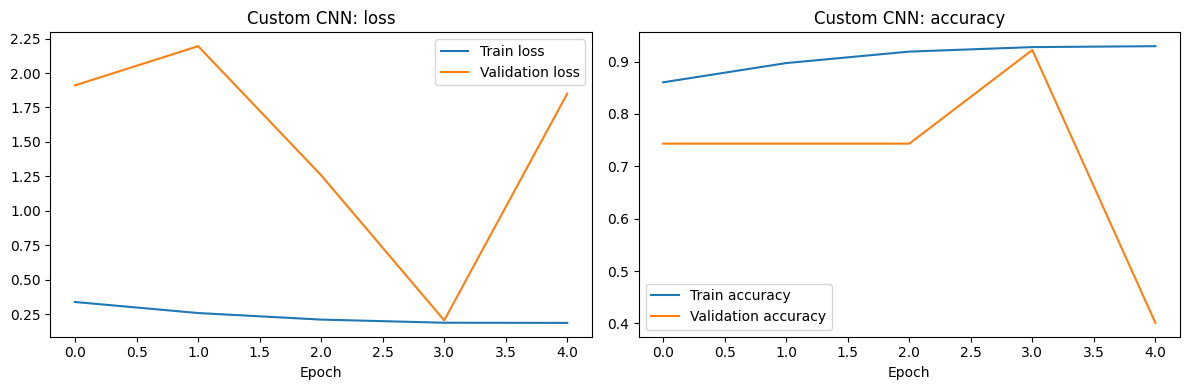

In [10]:
custom_model, custom_backbone = build_custom_cnn()
custom_model.summary()
histories["Custom CNN"] = train_model("Custom CNN", custom_model, custom_backbone)
trained_models["Custom CNN"] = custom_model
backbones["Custom CNN"] = custom_backbone
plot_history(histories["Custom CNN"], "Custom CNN")

## 11. Evaluation helper

In [11]:
def evaluate_model(model_name, model, dataset, split_name):
    y_true_batches = []
    for _, labels in dataset:
        y_true_batches.append(labels.numpy())
    y_true = np.concatenate(y_true_batches).astype(int)

    start = time.perf_counter()
    probabilities = model.predict(dataset, verbose=0)
    elapsed = time.perf_counter() - start
    y_pred = np.argmax(probabilities, axis=1)

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    try:
        auc = roc_auc_score((y_true == 1).astype(int), probabilities[:, 1])
    except ValueError:
        auc = float("nan")

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    results = {
        "model_name": model_name,
        "split_name": split_name,
        "model": model,
        "y_true": y_true,
        "y_pred": y_pred,
        "probabilities": probabilities,
        "classification_report": report,
        "confusion_matrix": cm,
        "roc_auc": auc,
        "inference_ms_per_image": elapsed * 1000 / len(y_true),
    }

    print(f"\n{model_name} — {split_name}-set classification report")
    display(pd.DataFrame(report).transpose().round(4))
    print(f"ROC-AUC (PNEUMONIA positive class): {auc:.4f}" if np.isfinite(auc) else "ROC-AUC undefined for this split")
    print("Approximate prediction time per image (batched):", round(results["inference_ms_per_image"], 3), "ms")

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(values_format="d")
    plt.title(f"{model_name} — {split_name} confusion matrix")
    plt.tight_layout()
    plt.show()
    return results

## 12. Evaluate the Custom CNN


Custom CNN — validation-set classification report


,precision,recall,f1-score,support
NORMAL,0.8804,0.8060,0.8416,201.0000
PNEUMONIA,0.9349,0.9622,0.9483,582.0000
accuracy,0.9221,0.9221,0.9221,0.9221
macro avg,0.9077,0.8841,0.8950,783.0000
weighted avg,0.9209,0.9221,0.9209,783.0000


ROC-AUC (PNEUMONIA positive class): 0.9680
Approximate prediction time per image (batched): 13.086 ms


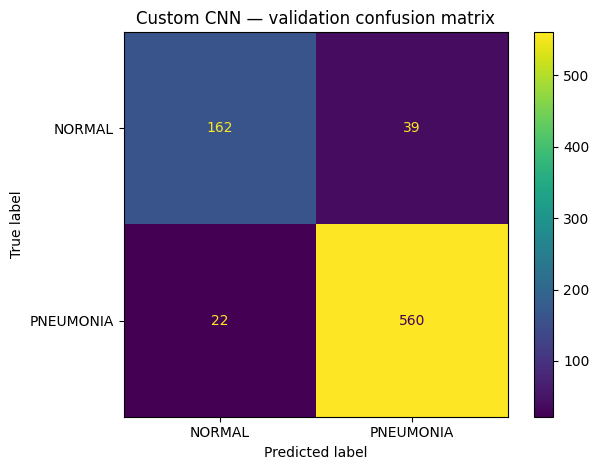

In [12]:
validation_results["Custom CNN"] = evaluate_model("Custom CNN", trained_models["Custom CNN"], val_ds, "validation")

## 13. Train DenseNet121

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "densenet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet_preprocess             │ (None, 224, 224, 3)    │             0 │
│ (DenseNetPreprocessing)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probs (Dense)             │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,039,554 (26.85 MB)

 Trainable params: 2,050 (8.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)


Training DenseNet121 — initial stage
Epoch 1/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 106s 608ms/step - accuracy: 0.8040 - loss: 0.4075 - val_accuracy: 0.9285 - val_loss: 0.1860 - learning_rate: 0.0010
Epoch 2/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.9056 - loss: 0.2300
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
139/139 ━━━━━━━━━━━━━━━━━━━━ 78s 562ms/step - accuracy: 0.9086 - loss: 0.2294 - val_accuracy: 0.8876 - val_loss: 0.2431 - learning_rate: 0.0010
Epoch 3/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 82s 561ms/step - accuracy: 0.9192 - loss: 0.2014 - val_accuracy: 0.9349 - val_loss: 0.1592 - learning_rate: 3.0000e-04
Epoch 4/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - accuracy: 0.9313 - loss: 0.1794
Epoch 4: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
139/139 ━━━━━━━━━━━━━━━━━━━━ 83s 567ms/step - accuracy: 0.9265 - loss: 0.1857 - val_accuracy: 0.9195 - val_loss: 0.1784 - learning_rate: 3.0000e-04
Epoch 5/5
139/139 ━━━━━━━━━━━━━

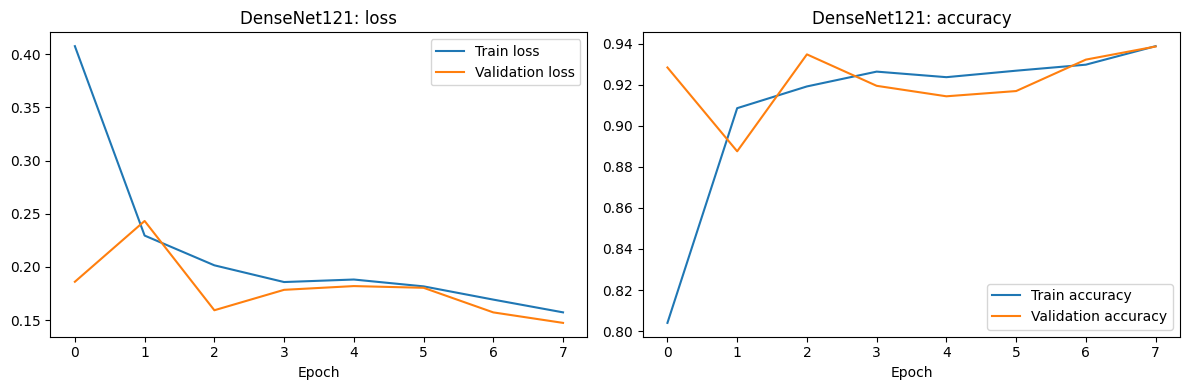


DenseNet121 — validation-set classification report


,precision,recall,f1-score,support
NORMAL,0.8283,0.9602,0.8894,201.0000
PNEUMONIA,0.9855,0.9313,0.9576,582.0000
accuracy,0.9387,0.9387,0.9387,0.9387
macro avg,0.9069,0.9457,0.9235,783.0000
weighted avg,0.9451,0.9387,0.9401,783.0000


ROC-AUC (PNEUMONIA positive class): 0.9895
Approximate prediction time per image (batched): 22.114 ms


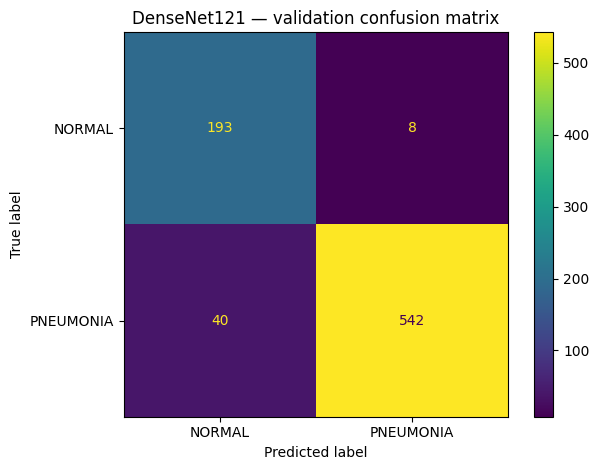

In [13]:
densenet_model, densenet_backbone = build_transfer_model("DenseNet121")
densenet_model.summary()
histories["DenseNet121"] = train_model("DenseNet121", densenet_model, densenet_backbone)
trained_models["DenseNet121"] = densenet_model
backbones["DenseNet121"] = densenet_backbone
plot_history(histories["DenseNet121"], "DenseNet121")
validation_results["DenseNet121"] = evaluate_model("DenseNet121", trained_models["DenseNet121"], val_ds, "validation")

## 14. Train EfficientNetB0

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probs (Dense)             │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,052,133 (15.46 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Training EfficientNetB0 — initial stage
Epoch 1/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 89s 574ms/step - accuracy: 0.8504 - loss: 0.3181 - val_accuracy: 0.9234 - val_loss: 0.1727 - learning_rate: 0.0010
Epoch 2/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.9142 - loss: 0.2064
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
139/139 ━━━━━━━━━━━━━━━━━━━━ 69s 480ms/step - accuracy: 0.9154 - loss: 0.1989 - val_accuracy: 0.9208 - val_loss: 0.1879 - learning_rate: 0.0010
Epoch 3/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 82s 478ms/step - accuracy: 0.9265 - loss: 0.1723 - val_accuracy: 0.9323 - val_loss: 0.1550 - learning_rate: 3.0000e-04
Epoch 4/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.9357 - loss: 0.1537
Epoch 4: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
139/139 ━━━━━━━━━━━━━━━━━━━━ 83s 600ms/step - accuracy: 0.9314 - loss: 0.1606 - val_accuracy: 0.9298 - val_loss: 0.1560 - learning_rate: 3.0000e-04
Epoch 5/5
139/139 ━━━━━━━━━━━

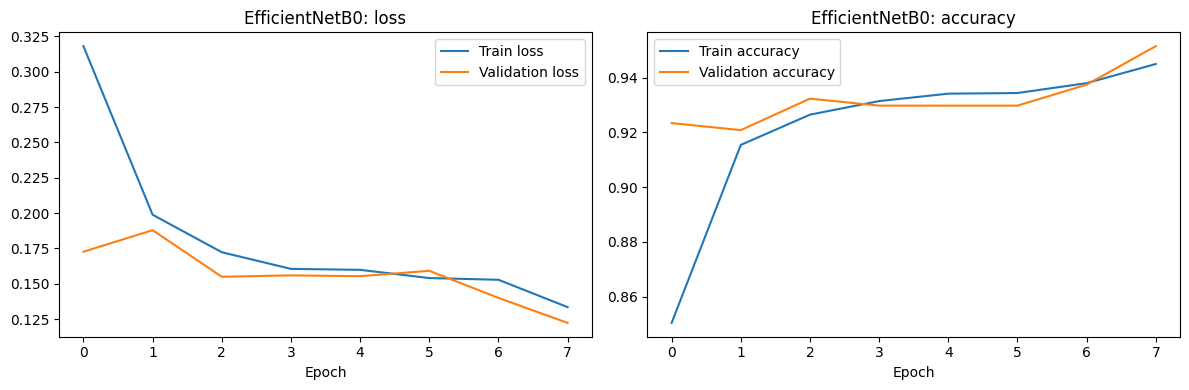


EfficientNetB0 — validation-set classification report


,precision,recall,f1-score,support
NORMAL,0.8655,0.9602,0.9104,201.0000
PNEUMONIA,0.9857,0.9485,0.9667,582.0000
accuracy,0.9515,0.9515,0.9515,0.9515
macro avg,0.9256,0.9543,0.9386,783.0000
weighted avg,0.9548,0.9515,0.9523,783.0000


ROC-AUC (PNEUMONIA positive class): 0.9896
Approximate prediction time per image (batched): 19.651 ms


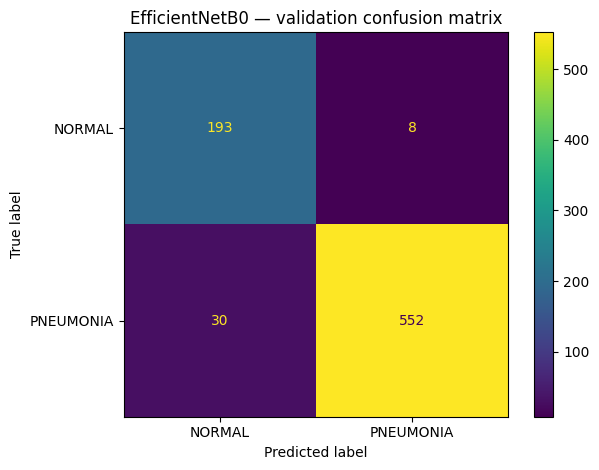

In [14]:
efficientnet_model, efficientnet_backbone = build_transfer_model("EfficientNetB0")
efficientnet_model.summary()
histories["EfficientNetB0"] = train_model("EfficientNetB0", efficientnet_model, efficientnet_backbone)
trained_models["EfficientNetB0"] = efficientnet_model
backbones["EfficientNetB0"] = efficientnet_backbone
plot_history(histories["EfficientNetB0"], "EfficientNetB0")
validation_results["EfficientNetB0"] = evaluate_model("EfficientNetB0", trained_models["EfficientNetB0"], val_ds, "validation")

## 15. Compare models and choose a candidate

,Model,Validation accuracy,NORMAL recall,PNEUMONIA recall,Validation macro F1,Validation ROC-AUC
0,EfficientNetB0,0.9515,0.9602,0.9485,0.9386,0.9896
1,DenseNet121,0.9387,0.9602,0.9313,0.9235,0.9895
2,Custom CNN,0.9221,0.8060,0.9622,0.8950,0.9680


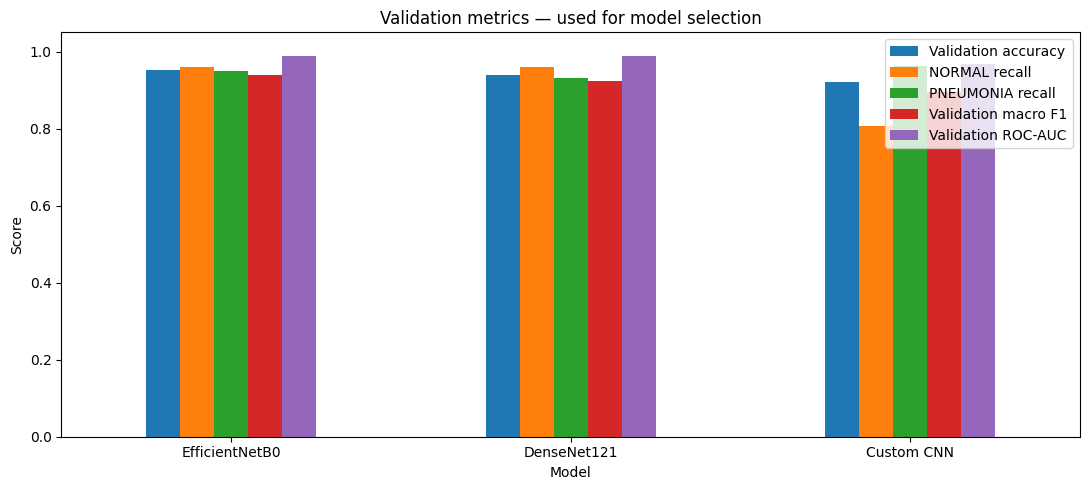

Candidate selected by validation macro F1: EfficientNetB0

Final held-out test evaluation for all models:

Custom CNN — test-set classification report


,precision,recall,f1-score,support
NORMAL,0.8710,0.2308,0.3649,234.0000
PNEUMONIA,0.6797,0.9795,0.8025,390.0000
accuracy,0.6987,0.6987,0.6987,0.6987
macro avg,0.7753,0.6051,0.5837,624.0000
weighted avg,0.7514,0.6987,0.6384,624.0000


ROC-AUC (PNEUMONIA positive class): 0.8478
Approximate prediction time per image (batched): 10.864 ms


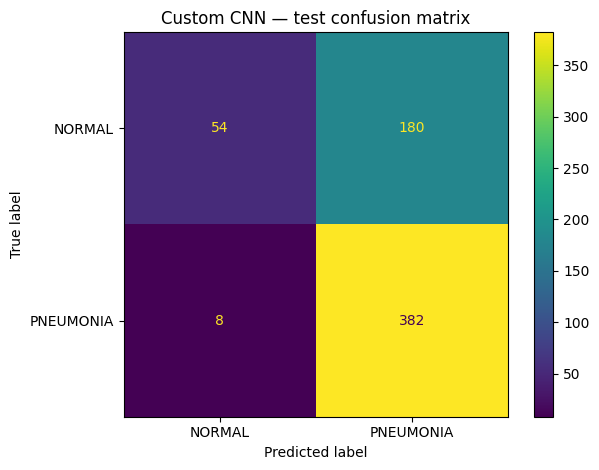


DenseNet121 — test-set classification report


,precision,recall,f1-score,support
NORMAL,0.9059,0.6581,0.7624,234.0000
PNEUMONIA,0.8238,0.9590,0.8863,390.0000
accuracy,0.8462,0.8462,0.8462,0.8462
macro avg,0.8648,0.8085,0.8243,624.0000
weighted avg,0.8546,0.8462,0.8398,624.0000


ROC-AUC (PNEUMONIA positive class): 0.9514
Approximate prediction time per image (batched): 16.405 ms


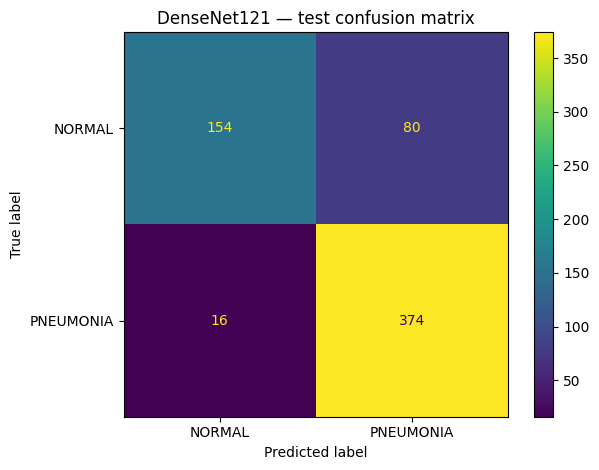


EfficientNetB0 — test-set classification report


,precision,recall,f1-score,support
NORMAL,0.9478,0.5427,0.6902,234.0000
PNEUMONIA,0.7816,0.9821,0.8705,390.0000
accuracy,0.8173,0.8173,0.8173,0.8173
macro avg,0.8647,0.7624,0.7803,624.0000
weighted avg,0.8439,0.8173,0.8029,624.0000


ROC-AUC (PNEUMONIA positive class): 0.9455
Approximate prediction time per image (batched): 16.431 ms


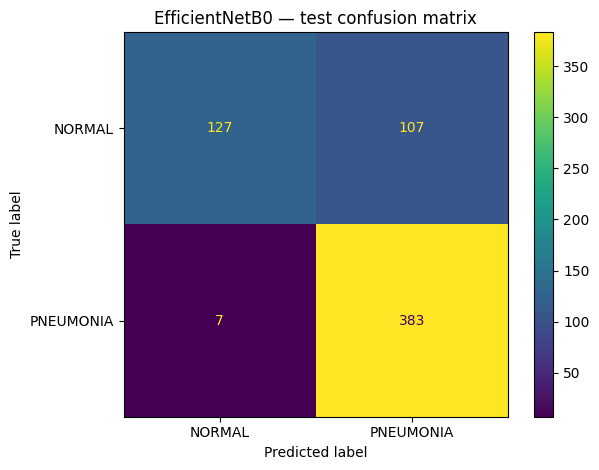

Final comparison (model order is determined by validation macro F1):


,Model,Validation macro F1,Test accuracy,Test NORMAL recall,Test PNEUMONIA recall,Test macro F1,Test weighted F1,Test ROC-AUC,Inference ms/image
0,EfficientNetB0,0.9386,0.8173,0.5427,0.9821,0.7803,0.8029,0.9455,16.4307
1,DenseNet121,0.9235,0.8462,0.6581,0.9590,0.8243,0.8398,0.9514,16.4046
2,Custom CNN,0.8950,0.6987,0.2308,0.9795,0.5837,0.6384,0.8478,10.8645


In [15]:
# First compare models on validation data. Select the candidate here, not on test performance.
validation_rows = []
for name, result in validation_results.items():
    report = result["classification_report"]
    validation_rows.append({
        "Model": name,
        "Validation accuracy": report["accuracy"],
        "NORMAL recall": report["NORMAL"]["recall"],
        "PNEUMONIA recall": report["PNEUMONIA"]["recall"],
        "Validation macro F1": report["macro avg"]["f1-score"],
        "Validation ROC-AUC": result["roc_auc"],
    })

validation_comparison_df = pd.DataFrame(validation_rows).sort_values(
    "Validation macro F1", ascending=False
).reset_index(drop=True)
display(validation_comparison_df.round(4))

validation_comparison_df.set_index("Model").plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))
plt.ylabel("Score")
plt.title("Validation metrics — used for model selection")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_model_name = validation_comparison_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_backbone = backbones[best_model_name]
print("Candidate selected by validation macro F1:", best_model_name)

# Now run final evaluation on the held-out test set. Do not change the model based on these scores.
print("\nFinal held-out test evaluation for all models:")
for name, model in trained_models.items():
    test_results[name] = evaluate_model(name, model, test_ds, "test")

test_rows = []
for name, result in test_results.items():
    report = result["classification_report"]
    val_report = validation_results[name]["classification_report"]
    test_rows.append({
        "Model": name,
        "Validation macro F1": val_report["macro avg"]["f1-score"],
        "Test accuracy": report["accuracy"],
        "Test NORMAL recall": report["NORMAL"]["recall"],
        "Test PNEUMONIA recall": report["PNEUMONIA"]["recall"],
        "Test macro F1": report["macro avg"]["f1-score"],
        "Test weighted F1": report["weighted avg"]["f1-score"],
        "Test ROC-AUC": result["roc_auc"],
        "Inference ms/image": result["inference_ms_per_image"],
    })

# Order rows by validation score, not test score, to keep the selection rule explicit.
comparison_df = pd.DataFrame(test_rows).sort_values(
    "Validation macro F1", ascending=False
).reset_index(drop=True)
print("Final comparison (model order is determined by validation macro F1):")
display(comparison_df.round(4))

## 16. Grad-CAM heatmap for the selected model

Grad-CAM highlights regions that influence a selected class score. It is a qualitative visualization, not a clinical explanation. The heatmap is shown for the model's predicted class by default.

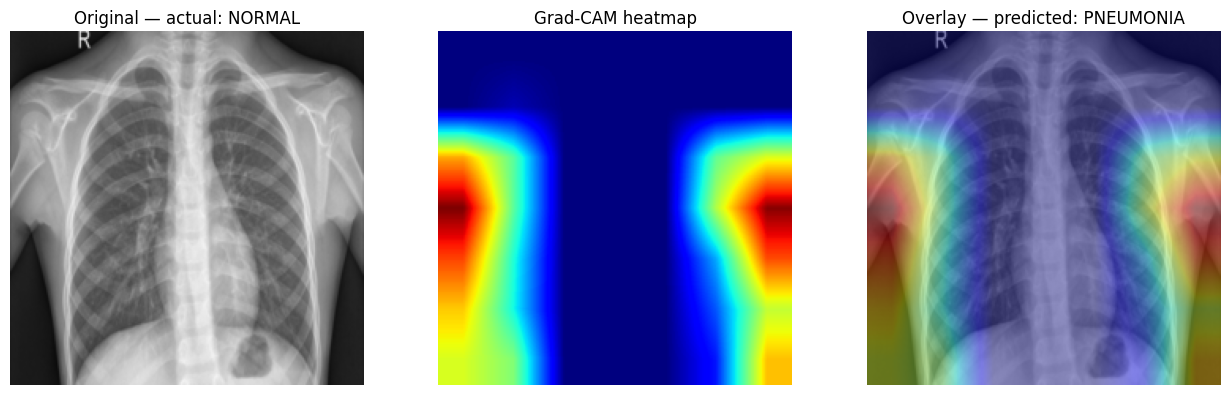

Model scores: {'NORMAL': 0.2455, 'PNEUMONIA': 0.7545}


In [16]:
def gradcam_heatmap(model_name, model, backbone, image_batch, class_index):
    """Return a normalized Grad-CAM heatmap for one raw-pixel image batch (shape 1,H,W,3)."""
    image_batch = tf.cast(image_batch, tf.float32)

    if backbone is None:
        # The custom CNN is a single Functional model, so expose its final convolution layer directly.
        grad_model = keras.Model(
            inputs=model.inputs,
            outputs=[model.get_layer("block4_conv").output, model.output],
        )
        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(image_batch, training=False)
            score = predictions[:, class_index]
    else:
        # Run the backbone and classification head inside the same tape so gradients can
        # be taken with respect to the feature maps produced by the backbone.
        with tf.GradientTape() as tape:
            x = model.get_layer("data_augmentation")(image_batch, training=False)
            if model_name == "DenseNet121":
                x = model.get_layer("densenet_preprocess")(x)
            conv_outputs = backbone(x, training=False)
            tape.watch(conv_outputs)
            x = model.get_layer("gap")(conv_outputs)
            x = model.get_layer("dropout_head")(x, training=False)
            predictions = model.get_layer("class_probs")(x)
            score = predictions[:, class_index]

    grads = tape.gradient(score, conv_outputs)
    if grads is None:
        raise RuntimeError("Could not compute Grad-CAM gradients for this model.")
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    max_value = tf.reduce_max(heatmap)
    heatmap = tf.where(max_value > 0, heatmap / (max_value + 1e-8), tf.zeros_like(heatmap))
    return heatmap.numpy(), predictions.numpy()[0]

# Use a held-out test image only to visualize the mechanics; it is not used for training.
example_path = str(test_paths[0])
raw_image, raw_label = decode_and_resize(tf.constant(example_path), tf.constant(test_labels[0]))
image_batch = tf.expand_dims(raw_image, 0)
heatmap, probs = gradcam_heatmap(best_model_name, best_model, best_backbone, image_batch, int(np.argmax(best_model(image_batch, training=False).numpy()[0])))
predicted_index = int(np.argmax(probs))
heatmap_resized = tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze()
heatmap_rgb = plt.cm.jet(heatmap_resized)[..., :3]
original = np.clip(raw_image.numpy() / 255.0, 0, 1)
overlay = np.clip(0.60 * original + 0.40 * heatmap_rgb, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(original)
axes[0].set_title(f"Original — actual: {CLASS_NAMES[int(test_labels[0])]}")
axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM heatmap")
axes[2].imshow(overlay)
axes[2].set_title(f"Overlay — predicted: {CLASS_NAMES[predicted_index]}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Model scores:", {CLASS_NAMES[i]: round(float(probs[i]), 4) for i in range(len(CLASS_NAMES))})

## 17. Predict on a new X-ray image

Run the following cell when you have a new image to test. In Google Colab, it opens a file-upload dialog. In a local Jupyter environment, set `IMAGE_PATH` to the image's path instead. The notebook resizes the image to the model input size and can optionally display Grad-CAM.

Saving test12.jpeg to test12.jpeg


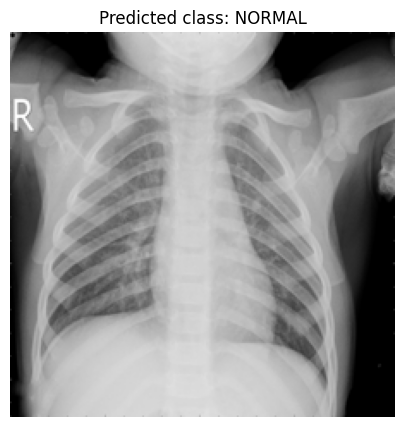

File: test12.jpeg
Model: EfficientNetB0
Scores: {'NORMAL': 0.9278, 'PNEUMONIA': 0.0722}
Educational model output only — not a medical diagnosis.


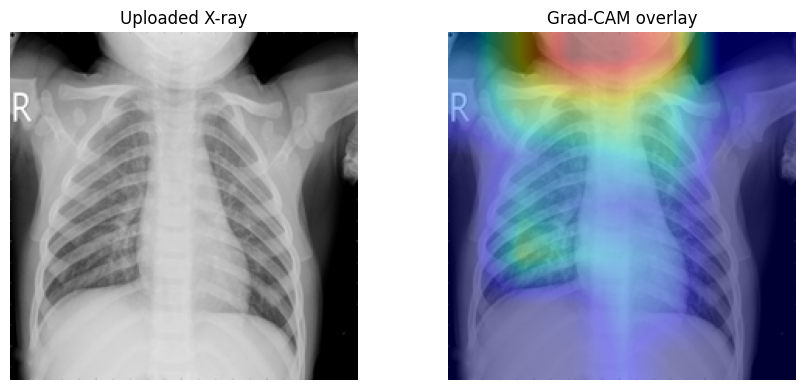

In [28]:
# In local Jupyter, change IMAGE_PATH to something like "./my_chest_xray.jpeg".
IMAGE_PATH = None

if IMAGE_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise ValueError("No file uploaded. Set IMAGE_PATH manually and rerun this cell.")
        image_name = next(iter(uploaded))
        image_for_prediction = Image.open(__import__("io").BytesIO(uploaded[image_name])).convert("RGB")
    except ImportError:
        raise ValueError("Set IMAGE_PATH to an image file path when running outside Google Colab.")
else:
    image_name = str(IMAGE_PATH)
    image_for_prediction = Image.open(IMAGE_PATH).convert("RGB")

image_for_prediction = image_for_prediction.resize(IMG_SIZE)
image_array = np.asarray(image_for_prediction, dtype=np.float32)  # remain in 0..255 scale
image_batch = tf.convert_to_tensor(image_array[None, ...], dtype=tf.float32)
probabilities = best_model.predict(image_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

plt.figure(figsize=(5, 5))
plt.imshow(image_for_prediction)
plt.axis("off")
plt.title(f"Predicted class: {CLASS_NAMES[predicted_index]}")
plt.show()
print("File:", image_name)
print("Model:", best_model_name)
print("Scores:", {CLASS_NAMES[i]: round(float(probabilities[i]), 4) for i in range(len(CLASS_NAMES))})
print("Educational model output only — not a medical diagnosis.")

try:
    uploaded_heatmap, _ = gradcam_heatmap(
        best_model_name, best_model, best_backbone, image_batch, predicted_index
    )
    uploaded_heatmap = tf.image.resize(uploaded_heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze()
    uploaded_rgb = plt.cm.jet(uploaded_heatmap)[..., :3]
    uploaded_overlay = np.clip(0.60 * (image_array / 255.0) + 0.40 * uploaded_rgb, 0, 1)
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(image_for_prediction)
    axes[0].set_title("Uploaded X-ray")
    axes[1].imshow(uploaded_overlay)
    axes[1].set_title("Grad-CAM overlay")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Grad-CAM visualization could not be generated for this image:", repr(exc))

## 18. Save the selected model and experiment summary

In [21]:
BEST_MODEL_PATH = Path("pneumonia_detection_best_model.keras")
best_model.save(BEST_MODEL_PATH)
comparison_df.to_csv("pneumonia_model_comparison.csv", index=False)
validation_comparison_df.to_csv("pneumonia_validation_comparison.csv", index=False)
print("Saved model:", BEST_MODEL_PATH.resolve())
print("Saved test comparison table:", Path("pneumonia_model_comparison.csv").resolve())
print("Saved validation comparison table:", Path("pneumonia_validation_comparison.csv").resolve())
print("Selected candidate:", best_model_name)

# In Google Colab, uncomment these lines to download the artifacts to your computer:
# from google.colab import files
# files.download(str(BEST_MODEL_PATH))
# files.download("pneumonia_model_comparison.csv")
# files.download("pneumonia_validation_comparison.csv")

Saved model: /content/pneumonia_detection_best_model.keras
Saved test comparison table: /content/pneumonia_model_comparison.csv
Saved validation comparison table: /content/pneumonia_validation_comparison.csv
Selected candidate: EfficientNetB0


## 19. Suggested project improvements

- Repeat the experiment with multiple random seeds and report mean/standard deviation.
- Tune a decision threshold on the validation set if the project prioritizes sensitivity to pneumonia; do not tune on the test set.
- Consider calibration, subgroup evaluation, and patient-level splits if suitable metadata is available.
- Add a Streamlit or FastAPI interface only after validating the notebook pipeline.
- Document the dataset's limitations and avoid presenting results as clinical performance.